# Chapter 6: Many Metrics, Long-Run Truth

This notebook runs every piece of code in the chapter, in order, with the chapter's text around it. Read the chapter on the site: [Many Metrics, Long-Run Truth](https://books.sugiv.fyi/lift/many-metrics.html). Everything is simulated from seeded code in `sim/`, so a run gives the same numbers as the book.

In [1]:
# Run this cell first. In Google Colab it fetches the companion repo; anywhere else, run the
# notebook from a clone of it. Either way it moves to the repo's root so `sim` can be imported.
import os
import pathlib
import sys

if "google.colab" in sys.modules:
    if not pathlib.Path("/content/lift-not-luck").exists():
        !git clone -q --depth 1 https://github.com/sugix/lift-not-luck /content/lift-not-luck
    %pip install -q pingouin
candidates = [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, pathlib.Path("/content/lift-not-luck")]
root = next(p for p in candidates if (p / "sim" / "parlo.py").is_file())
os.chdir(root)
sys.path.insert(0, str(root))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pingouin as pg
from scipy import stats
def glue(name, value, display=True):
    """In the book, glue() puts a computed number into the text. Here the numbers are already
    written into the text, so it only shows the value when asked to."""
    if display:
        from IPython.display import display as show
        show(value)

from sim import longrun as LR, style

style.apply()
pd.set_option("display.precision", 3)


def glue_num(name, value):
    glue(name, float(value), display=False)


z_all = LR.rubric_z(reps=2_000, seed=1)
p_all = 2 * stats.norm.sf(np.abs(z_all))
real = np.array([m in LR.REAL_GAINS for m in LR.RUBRIC])
glue_num("any_false", 100 * (p_all[:, ~real] < 0.05).any(axis=1).mean())

Here's the finding first. Juno's team scores every new tutor version on **25 rubric metrics**, each judged per lesson by an LLM grader and averaged per learner. Juno v3 genuinely improved three of them. But in 56% of readouts like this one, at least one of the other 22 also shows up as a "significant" win, purely by chance. Someone will put that win on a slide.

That's the first of five ways a correct experiment still produces a wrong story. This chapter closes Part I with all five. Each has a simple fix:

- **Many metrics:** control the false discovery rate.
- **Ramp-ups:** compare like with like, day by day.
- **Novelty:** watch the effect over time, not just on average.
- **Adding up wins:** measure the total with a long-term holdout.
- **Short-term proxies:** check that they actually predict the long term.

> **Note**
>
> The numbers come from `lift/sim/longrun.py`: Juno v3's rubric scores, a Streak Shield variant tested with a ramp-up, a livelier Juno persona, and a history of learners for building a surrogate for day-30 retention.

## Many metrics: one of them will win

Here's v3's readout: 1,500 learners per arm, sorted by p-value.

In [3]:
z = LR.rubric_z(seed=5)[0]
p = 2 * stats.norm.sf(np.abs(z))
reject_bh, p_bh = pg.multicomp(p, method="fdr_bh")
readout = pd.DataFrame({"metric": LR.RUBRIC, "z": z, "p-value": p, "BH-adjusted p": p_bh,
                        "truly improved": real}).sort_values("p-value").head(8)
readout.style.format({"z": "{:+.2f}", "p-value": "{:.4f}", "BH-adjusted p": "{:.3f}"}).hide(axis="index")

metric,z,p-value,BH-adjusted p,truly improved
recap quality,+4.71,0.0000,0.000,True
clarity,+4.46,0.0000,0.000,True
examples,+4.26,0.0000,0.000,True
confidence,+2.01,0.0442,0.276,False
pronunciation tips,-1.23,0.2198,0.829,False
follow-up questions,-1.21,0.2249,0.829,False
brevity,+1.14,0.2528,0.829,False
safety,+1.03,0.3028,0.829,False


In [4]:
fake = [m for m, r, ok in zip(LR.RUBRIC, p < 0.05, real) if r and not ok]
glue("fake_metric", fake[0] if fake else "none", display=False)

Four metrics clear p < 0.05. Three are real. The fourth, **confidence**, isn't: v3 didn't change it at all. With 22 metrics that truly didn't move, each with a 5% false-alarm rate, you expect about one false win per readout, and that's what you get.

The fix is to control the **false discovery rate (FDR)**: among the metrics you call winners, keep the expected share of false ones at or below 5%. The Benjamini-Hochberg procedure (Benjamini and Hochberg, 1995) does that with one line, `pg.multicomp(p, method="fdr_bh")`. It sorts the p-values and compares the $k$-th smallest with $0.05 \times k / 25$, so the bar is strict for the most significant result and relaxes as you go down the sorted list. Here it keeps the three real wins and drops the fake one.

Across 2,000 readouts:

In [5]:
rows = {}
for name, wins in [("no correction", p_all < 0.05),
                   ("Benjamini-Hochberg (FDR)", np.array([pg.multicomp(r, method="fdr_bh")[0] for r in p_all])),
                   ("Bonferroni (0.05 / 25 per metric)", p_all < 0.05 / 25)]:
    rows[name] = {"false wins per readout": wins[:, ~real].sum(axis=1).mean(),
                  "readouts with any false win": wins[:, ~real].any(axis=1).mean(),
                  "real gains found": wins[:, real].mean()}
pd.DataFrame(rows).T.style.format({"false wins per readout": "{:.2f}",
                                   "readouts with any false win": "{:.0%}", "real gains found": "{:.0%}"})

,false wins per readout,readouts with any false win,real gains found
no correction,1.07,56%,91%
Benjamini-Hochberg (FDR),0.16,10%,68%
Bonferroni (0.05 / 25 per metric),0.04,3%,58%


Benjamini-Hochberg removes most of the false wins and keeps most of the real ones. Bonferroni is stricter and pays for it in missed gains. For a dashboard of many metrics, FDR is the better trade.

Three habits matter more than the correction itself:

- **One decision metric, decided in advance** (Chapter 2). Correct the *other* metrics; don't let them decide.
- **Segments are metrics too.** "It works for iOS users in Brazil" is one of dozens of slices. Correct across them, or treat the finding as a hypothesis for the next test.
- **LLM-judge rubrics are correlated.** A judge that likes one answer tends to score it well on everything. Benjamini-Hochberg stays valid, or very nearly so, under this kind of positive correlation, which is one more reason to prefer it.

## Simpson's paradox: the ramp-up that reversed

Parlo tested a new Streak Shield design carefully: start the treatment at 5% of new learners, and ramp up to 50% over four days once nothing broke. Good engineering. But launch week also had a marketing push, so the learners who signed up in the first three days were keener than usual.

In [6]:
ramp = LR.ramp_test()
pooled = (ramp["treatment retained"].sum() / ramp["treatment learners"].sum()
          - ramp["control retained"].sum() / ramp["control learners"].sum())
ramp.assign(**{"control rate": ramp["control retained"] / ramp["control learners"],
               "treatment rate": ramp["treatment retained"] / ramp["treatment learners"]}) \
    [["day", "control learners", "treatment learners", "control rate", "treatment rate"]] \
    .style.format({"control rate": "{:.3f}", "treatment rate": "{:.3f}"}).hide(axis="index")

day,control learners,treatment learners,control rate,treatment rate
1,3800,200,0.460,0.465
2,3600,400,0.452,0.458
3,3200,800,0.445,0.474
4,2000,2000,0.283,0.317
5,2000,2000,0.300,0.308
6,2000,2000,0.306,0.321
7,2000,2000,0.306,0.323


In [7]:
strat = LR.stratified_lift(ramp)
glue_num("pooled", 100 * pooled)
glue_num("pooled_abs", -100 * pooled)
glue_num("strat", 100 * strat)

On every single day, the treatment beats control. Pool all seven days, though, and the treatment looks **4.7 points worse**.

That's **Simpson's paradox**. Control's learners are mostly from the keen launch days, when control had 80 to 95% of traffic. Treatment's learners are mostly from the ordinary days after the ramp. The pooled comparison is mostly comparing launch-week learners with later learners, which is Chapter 1's selection bias arriving through the calendar.

The fix is to compare within each day and then combine the daily differences, giving more weight to days with more balanced arms:

In [8]:
print(f"pooled: {100 * pooled:+.1f} points   day by day, combined: {100 * LR.stratified_lift(ramp):+.1f} points")

pooled: -4.7 points   day by day, combined: +1.8 points


The combined day-by-day estimate is +1.8 points: the right sign, and within noise of the true +1. The simplest rule, and the one most platforms follow: **only analyse the period when the split was fixed**, or stratify by allocation period. Never pool across a change in the split. The same applies whenever the traffic split changes mid-test, which bandits (Part II) do all the time; that's why Chapter 10 will need propensity weighting.

## Novelty: the effect that fades

Juno's team launches **Coach Juno**, a livelier persona with more encouragement and emoji. Existing learners in the test group get it from day 0. After one week, daily lessons are up several percent. Here's the effect by day over four weeks, from 40,000 learners per arm:

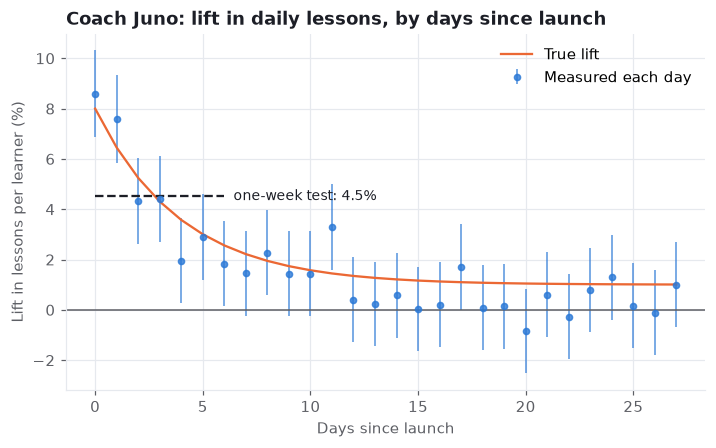

In [9]:
N = LR.novelty_test()
fig, ax = plt.subplots()
ax.errorbar(N.day, N["lift %"], yerr=1.96 * N["se %"], fmt="o", markersize=4,
            color=style.SERIES[0], ecolor=style.SERIES[0], elinewidth=1, alpha=0.8, label="Measured each day")
ax.plot(N.day, N["true lift %"], color=style.SERIES[1], linewidth=1.5, label="True lift")
ax.axhline(0, color=style.MUTED, linewidth=1)
wk1 = N["lift %"][:7].mean()
ax.hlines(wk1, 0, 6, color=style.INK, linewidth=1.5, linestyle="--")
ax.annotate(f"one-week test: {wk1:.1f}%", xy=(6, wk1), xytext=(6, 0), textcoords="offset points",
            va="center", fontsize=9, color=style.INK)
ax.set(title="Coach Juno: lift in daily lessons, by days since launch",
       xlabel="Days since launch", ylabel="Lift in lessons per learner (%)")
ax.legend(loc="upper right")
plt.show()

In [10]:
glue_num("nov_wk1", N["lift %"][:7].mean())
glue_num("nov_wk4", N["lift %"][21:].mean())
glue_num("nov_true", LR.novelty_lift(1000))

A one-week test reports 4.5%. The lasting effect is about 1%, and by the last week of the test the measured lift had fallen to 0.5%. The rest was curiosity: learners poking at the new persona because it was new.

The reverse also happens. A redesigned lesson screen can *hurt* for a week while learners relearn where things are, then help. That's a **primacy effect**, and a short test would kill a good change.

What I do about both:

- **Plot the effect by day since exposure**, not just the average. If it's still moving at the end, the test isn't finished.
- **Look at new users separately.** People who never saw the old version can't be excited by the change. If new users show the small, stable effect, that's your long-run number.
- **Keep a long-term holdout** for big changes: a small group that stays on the old version for months (Chapter 10).

Agent features are especially prone to novelty. A new persona, voice or capability is fun to try. Whether it's still used in week six is a different question, and the one that matters.

## Holdouts: adding up the quarter honestly

Chapter 4's winner's curse has a cumulative version. Every quarter, Parlo's team adds up the lifts of the features it shipped and reports the total, then wonders why the company's top-line numbers grew by much less. Here's a simulated quarter: 40 experiments, each measured with the usual noise, shipped if significantly positive.

In [11]:
quarter, holdout_measured = LR.quarter_of_launches()
shipped = quarter[quarter.shipped]
pd.Series({"experiments run": f"{len(quarter)}",
           "features shipped": f"{len(shipped)}",
           "sum of reported lifts": f"{shipped.reported_lift.sum():.1f}%",
           "sum of true lifts": f"{shipped.true_lift.sum():.1f}%",
           "quarter-long holdout measures": f"{holdout_measured:.1f}%"}).to_frame("this quarter")

,this quarter
experiments run,40
features shipped,5
sum of reported lifts,10.4%
sum of true lifts,5.1%
quarter-long holdout measures,6.0%


In [12]:
glue_num("q_shipped", len(shipped))
glue_num("q_reported", shipped.reported_lift.sum())
glue_num("q_true", shipped.true_lift.sum())
glue_num("q_holdout", holdout_measured)

The 5 shipped features claim 10.4% more lessons between them. Their true combined lift is 5.1%. Each test was fine on its own; selecting the lucky ones inflated the sum, exactly as in Chapter 4.

The fix is a **long-term holdout**: a small random group of learners, say 5%, who get *none* of the quarter's launches. At the end of the quarter, comparing everyone else with the holdout measures the combined effect of everything shipped, interactions included, with no selection. Here it reads 6.0%, close to the truth and a little over half of what the dashboards claimed.

Holdouts cost something: 5% of learners miss every improvement for a quarter, and some features (a redesign everyone talks about) can't be withheld. In practice teams refresh the holdout every quarter, and exclude legal or safety changes from it. Chapter 10 shows how to size a holdout and uses one to prove what a bandit added.

## Surrogates: when the short term predicts the long term

Day-30 retention is Parlo's north star, and it takes 30 days to measure, plus enrolment time. Can a week-one metric stand in for it? Week-one behaviour does predict day-30 retention: learners who show up on more days, and do more lessons, are more likely to stay.

A **surrogate index** (Athey et al., 2019) makes that precise. Use historical data, where you know both week-one behaviour and day-30 retention, to fit a model that predicts retention from week-one behaviour. In a new test, predict each learner's retention from their first week, and compare the predictions between arms. Here's the model, fitted on 100,000 past learners with Pingouin:

In [13]:
history = LR.surrogate_world(100_000, seed=1)
features = ["active_days_wk1", "lessons_wk1"]
model = pg.logistic_regression(history[features], history.retained_d30)
model[["names", "coef", "se"]]

,names,coef,se
0,Intercept,-2.329,0.017
1,active_days_wk1,0.349,0.005
2,lessons_wk1,0.097,0.003


In [14]:
coef = model.set_index("names").coef


def surrogate_index(df):
    logit = coef["Intercept"] + sum(coef[f] * df[f] for f in features)
    return 1 / (1 + np.exp(-logit))


rows = {}
for name, kwargs in [("Weekly Goals (builds a habit)", dict(engagement_shift=0.1)),
                     ("Notification blitz (nags)", dict(nag=0.5))]:
    c = LR.surrogate_world(30_000, seed=2)
    t = LR.surrogate_world(30_000, seed=3, **kwargs)
    big_c = LR.surrogate_world(400_000, seed=20)               # god view, for the truth
    big_t = LR.surrogate_world(400_000, seed=21, **kwargs)
    rows[name] = {"week-one active days": t.active_days_wk1.mean() - c.active_days_wk1.mean(),
                  "week-one lessons": t.lessons_wk1.mean() - c.lessons_wk1.mean(),
                  "surrogate says (points)": 100 * (surrogate_index(t).mean() - surrogate_index(c).mean()),
                  "true day-30 effect (points)": 100 * (big_t.retained_d30.mean() - big_c.retained_d30.mean())}
sur = pd.DataFrame(rows).T
sur.style.format("{:+.2f}")

,week-one active days,week-one lessons,surrogate says (points),true day-30 effect (points)
Weekly Goals (builds a habit),+0.13,+0.15,+1.21,+1.82
Notification blitz (nags),-0.01,+1.55,+3.02,-0.03


In [15]:
glue_num("sur_goal", sur.iloc[0]["surrogate says (points)"])
glue_num("sur_goal_true", sur.iloc[0]["true day-30 effect (points)"])
glue_num("sur_nag", sur.iloc[1]["surrogate says (points)"])
glue_num("sur_nag_true", sur.iloc[1]["true day-30 effect (points)"])

Two features, two very different outcomes:

- **Weekly Goals** builds a real habit, and that habit drives both week-one behaviour and retention. The surrogate predicts +1.2 points against a true +1.8: a bit conservative, but pointing the right way, three weeks early.
- **A notification blitz** pushes extra quick lessons in week one without changing anyone's habit. Lessons jump, so the surrogate predicts +3.0 points. The truth is essentially zero (-0.03).

The surrogate failed because the blitz moved the *proxy* without moving what the proxy usually signals. In the history, many lessons meant a keen learner; under the blitz, many lessons meant a pushy app. It's the same trap Chapter 8 shows with opens versus lessons, now in the form of a model. The formal requirement is that the treatment affects the long-term outcome **only through** the surrogates. Nagging breaks it.

How I use surrogates safely:

- **Validate on past experiments.** For tests where you eventually got the long-term answer, compare it with what the surrogate predicted. If they agree across many kinds of change, trust it more.
- **Be wary when the treatment targets the proxy directly.** Notifications, reminders and nudges all push short-term activity. For those, wait for the real outcome or keep a holdout.
- **Use rich surrogates.** Several behaviours (days active, lesson variety, streaks) are harder to game than one count.

For Juno, the same caution applies to automatic evaluations. An LLM-judge score is a surrogate for learning. A prompt that teaches Juno to *sound* helpful can raise the judge's score without raising completion or retention. Check judge scores against real outcomes regularly.

## Part I, in one page

| Chapter | Question | The habit |
|---|---|---|
| 1 | Did it cause the change? | Randomise; distrust opt-in comparisons |
| 2 | How big must the test be? | Size from the effect worth detecting; count the unit you randomised |
| 3 | Can I trust the data? | SRM by segment, A/A tests, exposure checks |
| 4 | What does the result mean? | Interval always; expected loss for decisions; shrink winners |
| 5 | Can I get it sooner? | CUPED; always-valid tests for guardrails |
| 6 | Is the story right? | FDR across metrics; fixed split; watch novelty; holdouts for the long run; validate surrogates |

Part II shows how bandits trade some of this rigour for faster gains, and how to win it back. Part III turns to the harder cases: when you can't randomise, or randomisation isn't enough.

> **In the wild**
>
> Google ran long-term holdouts on ad load and found that users gradually *learn*: show them more ads and, over months, they click on ads less, a learned "ad blindness" no short test could see (Hohnhold et al., 2015). Measuring that learning changed how many ads Google chose to show. The surrogate index has its own real test: Athey and colleagues (Athey et al., 2019) showed that short-term outcomes would have predicted the long-term earnings effects of a job-training programme years before the long-term data arrived.

## Pitfalls

- **Reporting the best of many metrics.** Apply FDR, or say how many metrics you looked at.
- **Pooling across a ramp-up.** Analyse the period with a fixed split, or compare within day.
- **Shipping on week one.** Check that the effect has stopped moving before you believe its size.
- **Trusting a proxy the treatment can push directly.** Opens, clicks, lesson starts and judge scores can all be moved without moving what you care about.

## Exercises

1. **More metrics.** Double the rubric to 50 metrics (still 3 real). How many false wins does an uncorrected readout produce now? How many does Benjamini-Hochberg allow?
2. **A gentler ramp.** Change `RAMP` so the treatment share is 50% from day 1. Does the pooled comparison still mislead? Why?
3. **New users only.** Modify `novelty_test` so that new learners joining each day see no novelty. How would you use their results to estimate the long-run effect earlier?
4. **Validate the surrogate.** Simulate ten past features: some shift engagement, some nag, some do both. Plot the surrogate's prediction against the true day-30 effect. Which features fall off the line?

## Further reading

Benjamini and Hochberg (Benjamini and Hochberg, 1995) introduced the false discovery rate. Athey, Chetty, Imbens and Kang (Athey et al., 2019) develop the surrogate index and when it can be trusted. Kohavi, Tang and Xu (Kohavi et al., 2020) discuss novelty, primacy and Simpson's paradox in online experiments.